<a href="https://colab.research.google.com/github/twyeh/university-physics/blob/main/magpylib_cube_magnet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install magpylib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 24.8 MB/s  0:00:01
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [magpylib]


Magnetic field B: [0.00000000e+00 0.00000000e+00 5.70001659e-05]


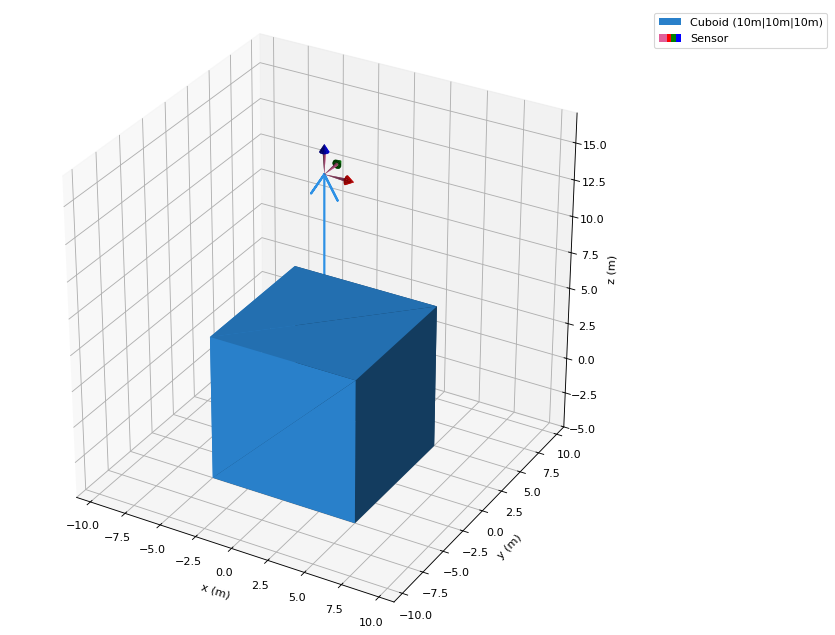

In [3]:
import magpylib as magp

# 1. 建立一個方塊磁鐵 (Cuboid magnet)，磁化方向沿著 Z 軸，強度為 1 階 (Tesla 級別等設定)
# 在新版 magpylib 中，Box 已更名為 Cuboid
cube = magp.magnet.Cuboid(magnetization=(0, 0, 1000), dimension=(10, 10, 10))

# 2. 建立一個感測器 (Sensor) 並放在磁鐵上方
sensor = magp.Sensor(position=(0, 0, 15))

# 3. 計算磁場 B (回傳 Tesla 單位)
b_field = cube.getB(sensor.position)
print("Magnetic field B:", b_field)

# 4. 進行 3D 視覺化
cube.show(sensor)

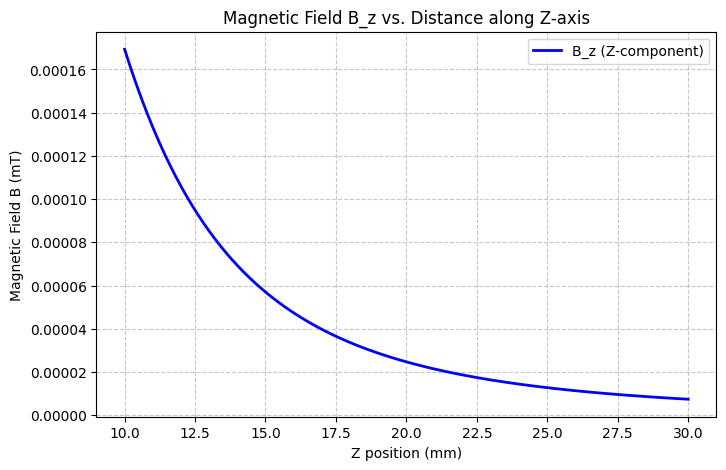

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 定義一系列不同的位置 (例如沿著 Z 軸從 10mm 到 30mm 均勻取 100 個點)
z_positions = np.linspace(10, 30, 100)
positions = [(0, 0, z) for z in z_positions]

# 2. 一次性計算所有位置的磁場強度 B
b_fields = cube.getB(positions)

# 3. 提取 Z 方向的磁場分量 (第 3 欄，索引為 2)
b_z = b_fields[:, 2]

# 4. 繪製磁場強度隨距離變化的折線圖
plt.figure(figsize=(8, 5))
plt.plot(z_positions, b_z, label='B_z (Z-component)', color='blue', linewidth=2)
plt.title('Magnetic Field B_z vs. Distance along Z-axis')
plt.xlabel('Z position (mm)')
plt.ylabel('Magnetic Field B (mT)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

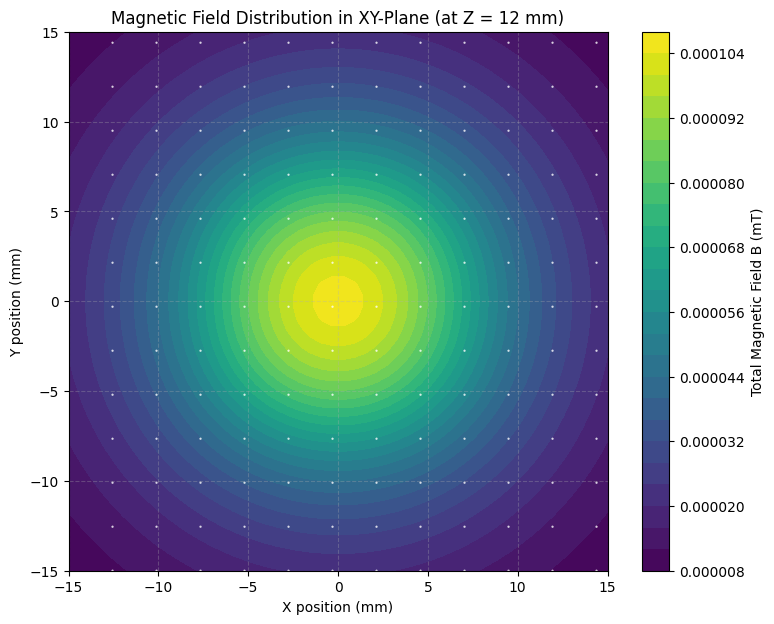

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 建立 XY 平面的二維網格 (例如 X 從 -15 到 15，Y 從 -15 到 15，高度固定在 Z = 12)
x_range = np.linspace(-15, 15, 50)
y_range = np.linspace(-15, 15, 50)
X, Y = np.meshgrid(x_range, y_range)

# 2. 將網格攤平並組合成三維座標格式 (X, Y, Z=12)
Z_height = 12
positions_2d = np.c_[X.ravel(), Y.ravel(), np.full(X.size, Z_height)]

# 3. 計算所有位置的磁場 B
b_fields_2d = cube.getB(positions_2d)

# 4. 將結果重新塑形回二維網格的形狀
Bx = b_fields_2d[:, 0].reshape(X.shape)
By = b_fields_2d[:, 1].reshape(X.shape)
Bz = b_fields_2d[:, 2].reshape(X.shape)

# 計算總磁場強度 B_total (B 的模長/大小)
B_total = np.sqrt(Bx**2 + By**2 + Bz**2)

# 5. 繪製 XY 平面的磁場強度分佈圖與向量場
plt.figure(figsize=(9, 7))

# 使用 contourf 繪製強度背景圖
contour = plt.contourf(X, Y, B_total, levels=30, cmap='viridis')
cbar = plt.colorbar(contour)
cbar.set_label('Total Magnetic Field B (mT)')

# 疊加磁場方向箭頭 (Vector field/Quiver plot)
# 為了圖表清晰，每隔 4 個點畫一個箭頭
skip = 4
plt.quiver(X[::skip, ::skip], Y[::skip, ::skip], Bx[::skip, ::skip], By[::skip, ::skip],
           color='white', pivot='middle', scale_units='xy', scale=0.5, alpha=0.8)

plt.title(f'Magnetic Field Distribution in XY-Plane (at Z = {Z_height} mm)')
plt.xlabel('X position (mm)')
plt.ylabel('Y position (mm)')
plt.gca().set_aspect('equal') # 保持長寬比 1:1
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

# 1. 先建立 XY 平面的二維基礎網格
x_range = np.linspace(-15, 15, 50)
y_range = np.linspace(-15, 15, 50)
X, Y = np.meshgrid(x_range, y_range)

# 2. 定義一個繪圖函數，接收 Z 高度作為參數
def plot_xy_at_z(z_val):
    # 將網格與給定的 Z 高度組合成三維座標
    positions_2d = np.c_[X.ravel(), Y.ravel(), np.full(X.size, z_val)]

    # 計算磁場 B
    b_fields_2d = cube.getB(positions_2d)

    # 重新塑形為 2D 矩陣
    Bx = b_fields_2d[:, 0].reshape(X.shape)
    By = b_fields_2d[:, 1].reshape(X.shape)
    Bz = b_fields_2d[:, 2].reshape(X.shape)

    B_total = np.sqrt(Bx**2 + By**2 + Bz**2)

    # 繪製圖表
    plt.figure(figsize=(9, 7))
    contour = plt.contourf(X, Y, B_total, levels=30, cmap='viridis', vmin=0, vmax=0.0002) # 固定顏色範圍以便觀察變化
    cbar = plt.colorbar(contour)
    cbar.set_label('Total Magnetic Field B (mT)')

    # 疊加磁場方向箭頭
    skip = 4
    plt.quiver(X[::skip, ::skip], Y[::skip, ::skip], Bx[::skip, ::skip], By[::skip, ::skip],
               color='white', pivot='middle', scale_units='xy', scale=0.5, alpha=0.8)

    plt.title(f'Magnetic Field Distribution in XY-Plane (at Z = {z_val:.1f} mm)')
    plt.xlabel('X position (mm)')
    plt.ylabel('Y position (mm)')
    plt.gca().set_aspect('equal')
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.show()

# 3. 建立互動滑桿 (高度範圍從 10mm 到 30mm)
interact(plot_xy_at_z, z_val=FloatSlider(min=10.0, max=30.0, step=1.0, value=12.0, description='Z Height (mm)'));

interactive(children=(FloatSlider(value=12.0, description='Z Height (mm)', max=30.0, min=10.0, step=1.0), Outp…

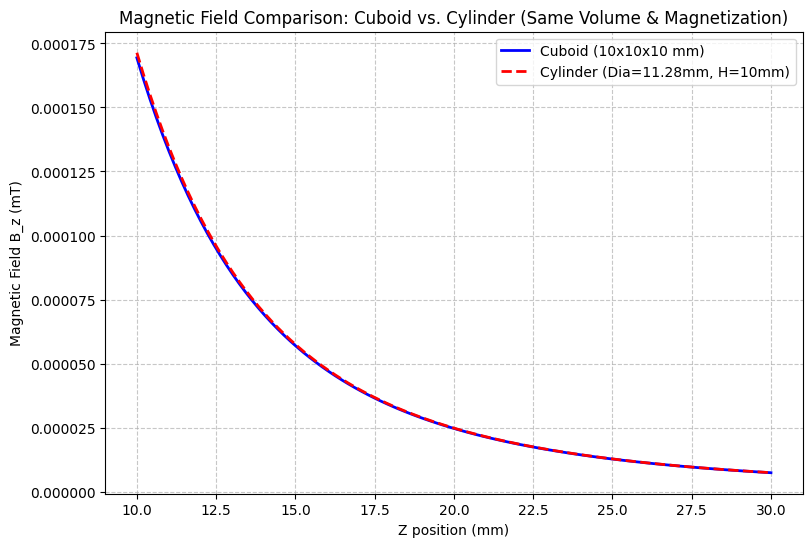

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import magpylib as magp

# 1. 建立一個體積與原方塊磁鐵相似的圓柱形磁鐵 (Cylinder)
# 方塊磁鐵體積為 10 * 10 * 10 = 1000 mm³
# 若圓柱高度也是 10 mm，要達到相同體積 1000 mm³：
# 體積 V = pi * r² * h -> r = sqrt(1000 / (10 * pi)) ≈ 5.64 mm (直徑 diameter ≈ 11.28 mm)
cylinder_magnet = magp.magnet.Cylinder(
    magnetization=(0, 0, 1000),
    dimension=(11.284, 10) # dimension 格式為 (直徑, 高度)
)

# 2. 定義觀測點 (沿著 Z 軸從高度 10mm 到 30mm)
z_positions = np.linspace(10, 30, 100)
positions = [(0, 0, z) for z in z_positions]

# 3. 分別計算方塊與圓柱磁鐵的磁場 B (Z 分量)
b_cuboid = cube.getB(positions)[:, 2]
b_cylinder = cylinder_magnet.getB(positions)[:, 2]

# 4. 繪製對比圖表
plt.figure(figsize=(9, 6))
plt.plot(z_positions, b_cuboid, label='Cuboid (10x10x10 mm)', color='blue', linewidth=2)
plt.plot(z_positions, b_cylinder, label='Cylinder (Dia=11.28mm, H=10mm)', color='red', linestyle='--', linewidth=2)
plt.title('Magnetic Field Comparison: Cuboid vs. Cylinder (Same Volume & Magnetization)')
plt.xlabel('Z position (mm)')
plt.ylabel('Magnetic Field B_z (mT)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

正在產生磁鐵陣列的 3D 預覽圖...


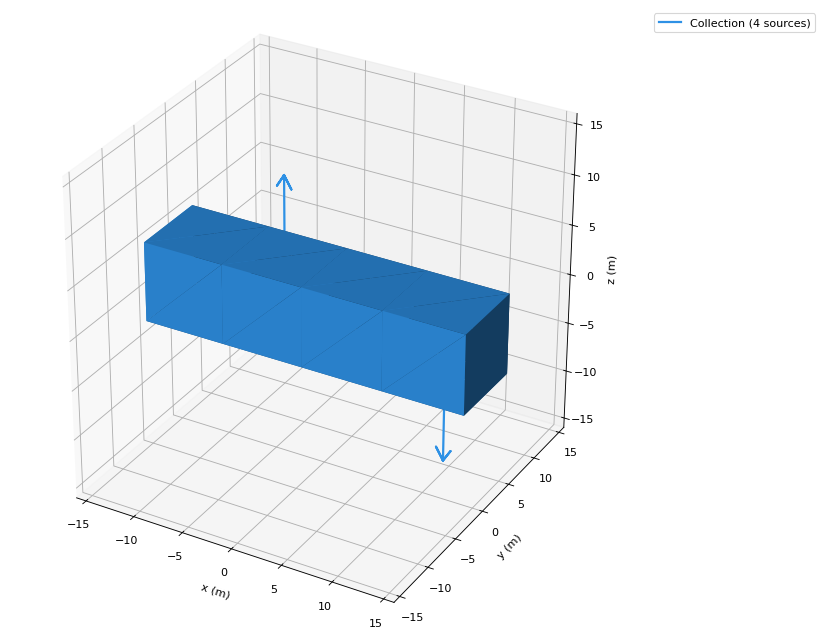

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import magpylib as magp

# 1. 建立一個空集合 (Collection) 用來組合多個磁鐵
magnet_array = magp.Collection()

# 2. 定義單個方塊磁鐵的尺寸與磁化強度大小
size = 8  # 每個磁鐵為 8x8x8 mm
mag_val = 1000  # 1000 mT (1 Tesla)

# 3. 建立一個 4 顆磁鐵排成一列的簡易 Halbach 陣列 (或是交錯陣列)
# 藉由旋轉不同磁鐵的磁化方向，我們可以在磁鐵上方增強磁場，下方削弱磁場
positions = [-12, -4, 4, 12]  # 沿著 X 軸排列

# 磁化方向向量組合：[向右, 向上, 向左, 向下]
magnetizations = [
    (mag_val, 0, 0),   # 1. 沿著 +X
    (0, 0, mag_val),   # 2. 沿著 +Z (朝上)
    (-mag_val, 0, 0),  # 3. 沿著 -X
    (0, 0, -mag_val)   # 4. 沿著 -Z (朝下)
]

for pos, mag in zip(positions, magnetizations):
    magnet = magp.magnet.Cuboid(
        magnetization=mag,
        dimension=(size, size, size),
        position=(pos, 0, 0) # 擺放在不同 X 座標，Y=0, Z=0
    )
    magnet_array.add(magnet)

# 4. 顯示陣列的 3D 幾何佈局
print("正在產生磁鐵陣列的 3D 預覽圖...")
magnet_array.show()

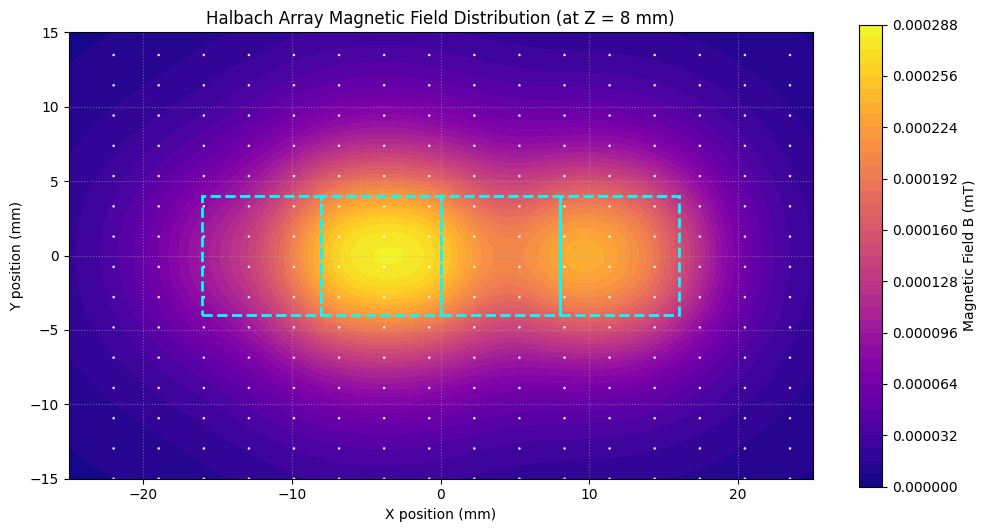

In [9]:
# 5. 計算陣列上方 (Z = 8 mm) 的磁場強度分佈並進行 2D 視覺化
x_grid = np.linspace(-25, 25, 100)
y_grid = np.linspace(-15, 15, 60)
X, Y = np.meshgrid(x_grid, y_grid)

# 定義觀察平面高度在磁鐵頂部上方 4mm 處 (磁鐵中心在 Z=0，厚度一半是 4mm，所以 Z = 8mm)
Z_height = 8
obs_positions = np.c_[X.ravel(), Y.ravel(), np.full(X.size, Z_height)]

# 計算集合中所有磁鐵對這些點產生的總磁場
B_array = magnet_array.getB(obs_positions)

# 重新塑形並計算總磁場強度
Bx_arr = B_array[:, 0].reshape(X.shape)
By_arr = B_array[:, 1].reshape(X.shape)
Bz_arr = B_array[:, 2].reshape(X.shape)
B_total_arr = np.sqrt(Bx_arr**2 + By_arr**2 + Bz_arr**2)

# 繪製磁場分佈與向量箭頭
plt.figure(figsize=(12, 6))
contour = plt.contourf(X, Y, B_total_arr, levels=40, cmap='plasma')
cbar = plt.colorbar(contour)
cbar.set_label('Magnetic Field B (mT)')

# 繪製向量箭頭 (X 和 Y 方向)
skip_x, skip_y = 6, 4
plt.quiver(X[::skip_y, ::skip_x], Y[::skip_y, ::skip_x],
           Bx_arr[::skip_y, ::skip_x], By_arr[::skip_y, ::skip_x],
           color='white', pivot='middle', scale_units='xy', scale=1.2, alpha=0.9)

# 標示出磁鐵實體在 XY 平面的投影位置
for pos in positions:
    rect = plt.Rectangle((pos - size/2, -size/2), size, size,
                         facecolor='none', edgecolor='cyan', linewidth=2, linestyle='--')
    plt.gca().add_patch(rect)

plt.title(f'Halbach Array Magnetic Field Distribution (at Z = {Z_height} mm)')
plt.xlabel('X position (mm)')
plt.ylabel('Y position (mm)')
plt.gca().set_aspect('equal')
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

### 模擬 Halbach 陣列移動時的動態磁場變化
在這個模擬中，我們假設**感測器固定在空間中的原點上方** $(0, 0, 8)\text{ mm}$，而整個 **Halbach 陣列沿著 X 軸從左向右滑動**。我們會記錄感測器在移動過程中所接收到的即時磁場三維分量。

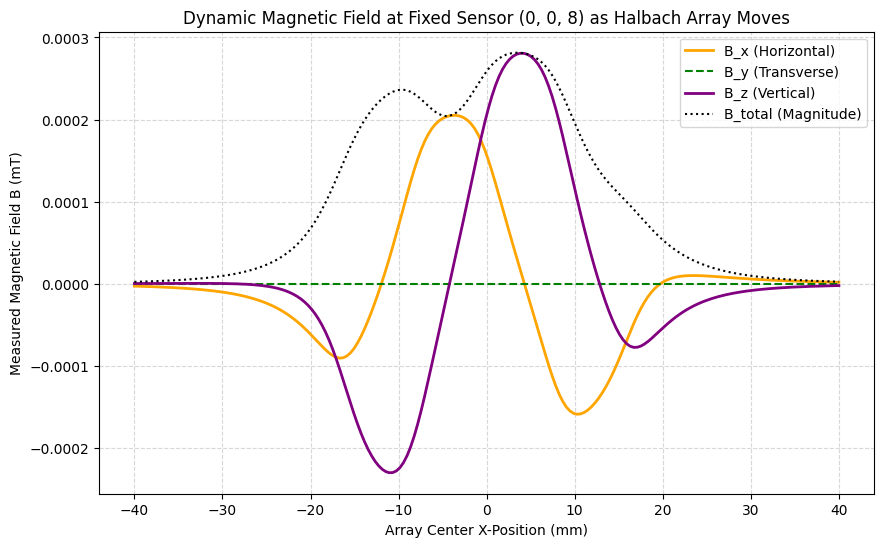

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import magpylib as magp

# 1. 定義固定的感測器位置 (X=0, Y=0, 高度 Z=8 mm)
sensor_pos = np.array([0, 0, 8])

# 2. 定義陣列移動的 X 軸路徑位置 (從 -40 mm 到 40 mm 均勻取 200 個時間點)
movement_steps = np.linspace(-40, 40, 200)

# 用於儲存每個位置下，感測器量測到的 B 向量
b_dynamic_results = []

# 3. 模擬移動過程
for x_offset in movement_steps:
    # 暫時將整個磁鐵陣列集合移動到目標位置 (x_offset, 0, 0)
    magnet_array.position = (x_offset, 0, 0)

    # 計算感測器點的磁場
    b_at_sensor = magnet_array.getB(sensor_pos)
    b_dynamic_results.append(b_at_sensor)

# 轉為 numpy array 以方便切片
b_dynamic_results = np.array(b_dynamic_results)

# 4. 將陣列位置重置回原點 (避免影響後續的其他模擬)
magnet_array.position = (0, 0, 0)

# 5. 繪製動態磁場變化圖
plt.figure(figsize=(10, 6))
plt.plot(movement_steps, b_dynamic_results[:, 0], label='B_x (Horizontal)', color='orange', linewidth=2)
plt.plot(movement_steps, b_dynamic_results[:, 1], label='B_y (Transverse)', color='green', linewidth=1.5, linestyle='--')
plt.plot(movement_steps, b_dynamic_results[:, 2], label='B_z (Vertical)', color='purple', linewidth=2)

# 計算總磁場強度並繪製
b_total_dynamic = np.linalg.norm(b_dynamic_results, axis=1)
plt.plot(movement_steps, b_total_dynamic, label='B_total (Magnitude)', color='black', linewidth=1.5, linestyle=':')

plt.title('Dynamic Magnetic Field at Fixed Sensor (0, 0, 8) as Halbach Array Moves')
plt.xlabel('Array Center X-Position (mm)')
plt.ylabel('Measured Magnetic Field B (mT)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### 模擬 Halbach 陣列旋轉時的動態磁場變化
在此模擬中，**感測器保持在原點上方固定位置** $(0, 0, 8)\text{ mm}$，而整個 **Halbach 陣列在原點 (Z軸) 進行從 0 到 360 度的原地旋轉**。我們將繪製磁場的三維分量與旋轉角度之間的關係曲線。

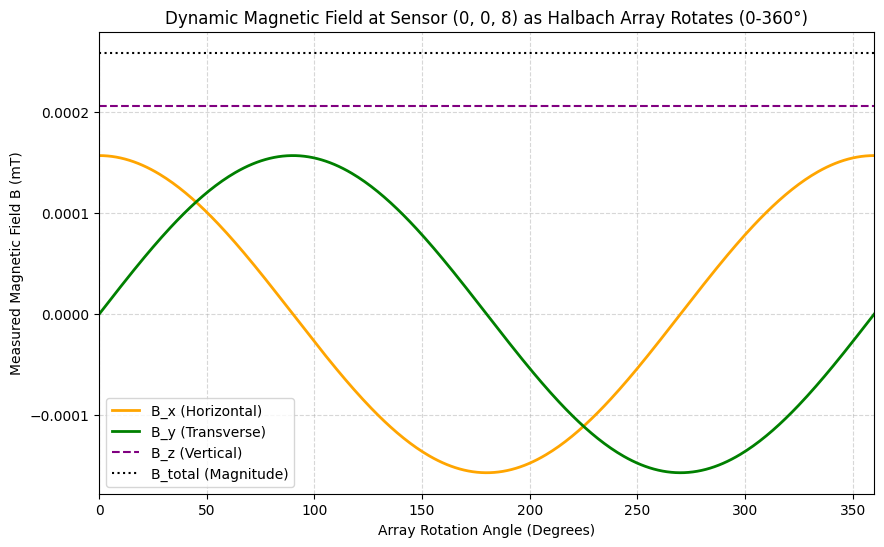

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import magpylib as magp

# 1. 定義固定的感測器位置 (高度 Z = 8 mm)
sensor_pos = np.array([0, 0, 8])

# 2. 定義旋轉角度的步進 (0 到 360 度，均勻取 360 個點)
rotation_angles = np.linspace(0, 360, 360)

b_rotation_results = []

# 3. 模擬旋轉過程
for angle in rotation_angles:
    # 重置陣列到初始姿態（不旋轉）
    magnet_array.orientation = None

    # 繞著 Z 軸旋轉指定的角度 (單位：度)
    magnet_array.rotate_from_angax(angle, 'z')

    # 計算固定感測器處的磁場
    b_at_sensor = magnet_array.getB(sensor_pos)
    b_rotation_results.append(b_at_sensor)

# 轉為 numpy array 以便分析與切片
b_rotation_results = np.array(b_rotation_results)

# 4. 重置陣列的旋轉狀態 (回歸到無旋轉的初始姿態)
magnet_array.orientation = None

# 5. 繪製旋轉動態磁場變化圖
plt.figure(figsize=(10, 6))
plt.plot(rotation_angles, b_rotation_results[:, 0], label='B_x (Horizontal)', color='orange', linewidth=2)
plt.plot(rotation_angles, b_rotation_results[:, 1], label='B_y (Transverse)', color='green', linewidth=2)
plt.plot(rotation_angles, b_rotation_results[:, 2], label='B_z (Vertical)', color='purple', linewidth=1.5, linestyle='--')

# 計算總磁場強度並繪製
b_total_rot = np.linalg.norm(b_rotation_results, axis=1)
plt.plot(rotation_angles, b_total_rot, label='B_total (Magnitude)', color='black', linewidth=1.5, linestyle=':')

plt.title('Dynamic Magnetic Field at Sensor (0, 0, 8) as Halbach Array Rotates (0-360°)')
plt.xlabel('Array Rotation Angle (Degrees)')
plt.ylabel('Measured Magnetic Field B (mT)')
plt.xlim(0, 360)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()